# Part 3: SHAP Explainability Analysis
This notebook provides visual and statistical proof of the explainability layer's reliability.
1. **Global Summary Plot**: Shows overall feature importance.
2. **Stability Check**: Proves that the top SHAP features remain stable across cross-validation folds.
3. **JSON Contract Sanity Check**: Demonstrates the exact input the LLM will receive.


In [1]:
import pandas as pd
import numpy as np
import pickle
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

import sys
sys.path.append('../models')
from modeling_pipeline import engineer_features
from shap_explainer import SHAPExplainer

%matplotlib inline


In [2]:
# Load data
df = pd.read_csv('../datasets/primary_dataset_clean.csv')
df = engineer_features(df)

label_map = {'Low': 0, 'Moderate': 1, 'High': 2}
df['Target'] = df['Risk_Category'].map(label_map)

X = df.drop(columns=['Risk_Category', 'Target'])
y = df['Target']

# Load frozen model
with open('../models/final_model.pkl', 'rb') as f:
    model = pickle.load(f)


## 1. Global Feature Importance (Summary Plot)


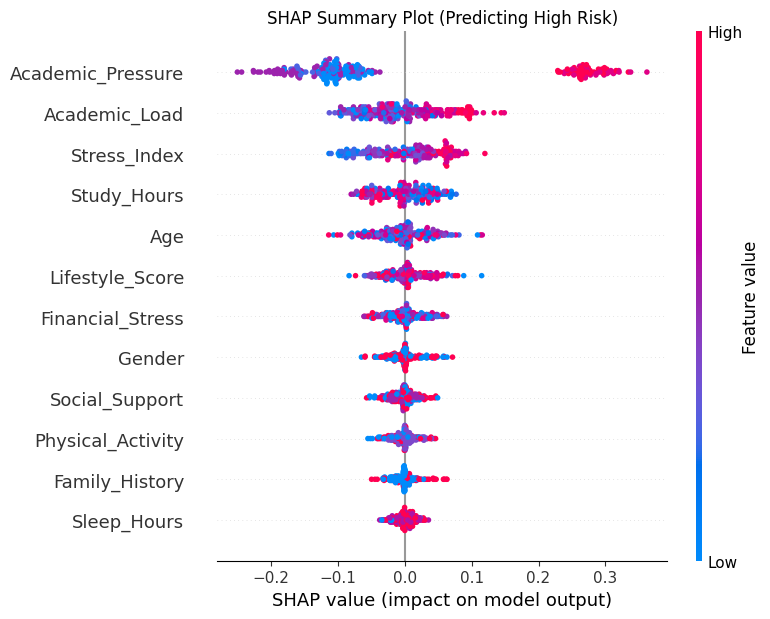

In [3]:
# Generate SHAP values on a representative sample so the notebook is reproducible in a live demo
X_sample = X.sample(min(250, len(X)), random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# For multi-class, we visualize the High Risk class (index 2)
if isinstance(shap_values, list):
    high_class_shap = shap_values[2]
else:
    high_class_shap = shap_values[:, :, 2]
    
shap.summary_plot(high_class_shap, X_sample, show=False)
plt.title('SHAP Summary Plot (Predicting High Risk)')
plt.tight_layout()
plt.show()


## 2. SHAP Stability Check across K-Folds


In [4]:
# We will train models across 5 folds and check if the top 3 features for the 'High' class stay consistent
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

top_features_per_fold = []

for train_idx, test_idx in cv.split(X, y):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    
    # Train a new RF model matching the final parameters
    # Note: final_model was RF with n_estimators=50, max_depth=None based on tuning
    fold_model = RandomForestClassifier(n_estimators=50, random_state=42)
    fold_model.fit(X_train, y_train)
    
    fold_explainer = shap.TreeExplainer(fold_model)
    X_train_sample = X_train.sample(min(100, len(X_train)), random_state=42 + len(top_features_per_fold))
    fold_shap_vals = fold_explainer.shap_values(X_train_sample)
    
    if isinstance(fold_shap_vals, list):
        high_class_shap = fold_shap_vals[2]
    else:
        high_class_shap = fold_shap_vals[:, :, 2]
        
    # Get mean absolute SHAP value per feature
    mean_abs_shap = np.abs(high_class_shap).mean(axis=0)
    top_3_idx = np.argsort(mean_abs_shap)[-3:]
    top_3_features = set(X.columns[top_3_idx])
    top_features_per_fold.append(top_3_features)

print("Top 3 SHAP features per fold:")
for i, features in enumerate(top_features_per_fold):
    print(f"Fold {i+1}: {features}")

# Compute intersection of top features across all folds to prove stability
common_features = set.intersection(*top_features_per_fold)
print(f"\nConsistently top 3 across ALL folds: {common_features}")


Top 3 SHAP features per fold:
Fold 1: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}
Fold 2: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}
Fold 3: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}
Fold 4: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}
Fold 5: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}

Consistently top 3 across ALL folds: {'Stress_Index', 'Academic_Load', 'Academic_Pressure'}


## 3. JSON Contract Sanity Checks


In [5]:
# We will use the SHAPExplainer service to generate JSON contracts for a Low risk and a High risk case
json_explainer = SHAPExplainer(model_path='../models/final_model.pkl', data_path='../datasets/primary_dataset_clean.csv')

# Find a predicted High risk case
probas = model.predict_proba(X)
high_preds = np.where(np.argmax(probas, axis=1) == 2)[0]
low_preds = np.where(np.argmax(probas, axis=1) == 0)[0]

high_row = X.iloc[high_preds[0]].to_dict()
low_row = X.iloc[low_preds[0]].to_dict()

print("=== HIGH RISK SANITY CHECK ===")
print(json_explainer.explain(high_row))

print("\n\n=== LOW RISK SANITY CHECK ===")
print(json_explainer.explain(low_row))


=== HIGH RISK SANITY CHECK ===
{
  "risk_label": "High",
  "risk_probabilities": {
    "Low": 0.0,
    "Moderate": 0.04,
    "High": 0.96
  },
  "top_factors": [
    {
      "feature": "Academic_Pressure",
      "shap_value": 0.3248,
      "direction": "increases_risk"
    },
    {
      "feature": "Stress_Index",
      "shap_value": 0.0655,
      "direction": "increases_risk"
    },
    {
      "feature": "Academic_Load",
      "shap_value": 0.0206,
      "direction": "decreases_risk"
    },
    {
      "feature": "Study_Hours",
      "shap_value": 0.0169,
      "direction": "increases_risk"
    }
  ]
}


=== LOW RISK SANITY CHECK ===
{
  "risk_label": "Low",
  "risk_probabilities": {
    "Low": 0.7,
    "Moderate": 0.1,
    "High": 0.2
  },
  "top_factors": [
    {
      "feature": "Academic_Pressure",
      "shap_value": 0.1466,
      "direction": "decreases_risk"
    },
    {
      "feature": "Academic_Load",
      "shap_value": 0.1031,
      "direction": "decreases_risk"
    },
  